In [20]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [21]:
# Load results from both models
opus = pd.read_csv("results/target_agent_results.csv")
haiku = pd.read_csv("results_haiku_low/target_agent_results.csv")

opus["model_name"] = "Opus"
haiku["model_name"] = "Haiku"

df = pd.concat([opus, haiku], ignore_index=True)

print("Total trials:", len(df))
display(df.groupby(["model_name", "condition_name"]).size())

Total trials: 180


model_name  condition_name                       
Haiku       High-Rep Majority, Majority Correct      15
            High-Rep Majority, Majority Incorrect    15
            High-Rep Minority, Majority Correct      15
            High-Rep Minority, Majority Incorrect    15
            No Reputation, Majority Correct          15
            No Reputation, Majority Incorrect        15
Opus        High-Rep Majority, Majority Correct      15
            High-Rep Majority, Majority Incorrect    15
            High-Rep Minority, Majority Correct      15
            High-Rep Minority, Majority Incorrect    15
            No Reputation, Majority Correct          15
            No Reputation, Majority Incorrect        15
dtype: int64

In [22]:
# Check parsing, errors, and experimental balance
print("Initial parsing:", df["initial_parse_ok"].sum())
print("Final parsing:", df["final_parse_ok"].sum())
print("Errors:", df["error"].notna().sum())

print("\nMajority correctness:")
print(df["majority_correct"].value_counts())

Initial parsing: 180
Final parsing: 180
Errors: 0

Majority correctness:
majority_correct
True     90
False    90
Name: count, dtype: int64


In [23]:
# Determine the correct answer
df["correct_answer"] = df["majority_answer"].where(
    df["majority_correct"],
    df["minority_answer"]
)

# Accuracy and answer switching
df["initial_correct"] = (
    df["target_initial_answer"] == df["correct_answer"]
)
df["final_correct"] = (
    df["target_final_answer"] == df["correct_answer"]
)
df["switched"] = (
    df["target_initial_answer"] != df["target_final_answer"]
)

# Agreement with peer groups
df["followed_majority"] = (
    df["target_final_answer"] == df["majority_answer"]
)
df["followed_minority"] = (
    df["target_final_answer"] == df["minority_answer"]
)

# Agreement with the high-reputation group
df["followed_high_rep"] = pd.Series(
    pd.NA, index=df.index, dtype="boolean"
)

for group, column in [
    ("high_rep_majority", "followed_majority"),
    ("high_rep_minority", "followed_minority")
]:
    mask = df["reputation_condition"] == group
    df.loc[mask, "followed_high_rep"] = df.loc[mask, column]

print("Metrics calculated.")

Metrics calculated.


In [24]:
# Compare performance across all six conditions
summary = (
    df.groupby(["model_name", "condition_name"])
    .agg(
        trials=("final_correct", "size"),
        initial_accuracy=("initial_correct", "mean"),
        final_accuracy=("final_correct", "mean"),
        switching_rate=("switched", "mean"),
        majority_rate=("followed_majority", "mean"),
        high_rep_rate=("followed_high_rep", "mean")
    )
    .reset_index()
)

metrics = [
    "initial_accuracy", "final_accuracy",
    "switching_rate", "majority_rate", "high_rep_rate"
]

summary[metrics] = (summary[metrics] * 100).round(1)

display(summary)

,model_name,condition_name,trials,initial_accuracy,final_accuracy,switching_rate,majority_rate,high_rep_rate
0,Haiku,"High-Rep Majority, Majority Correct",15,100.0,100.0,0.0,100.0,100.0
1,Haiku,"High-Rep Majority, Majority Incorrect",15,93.3,100.0,6.7,0.0,0.0
2,Haiku,"High-Rep Minority, Majority Correct",15,100.0,100.0,0.0,100.0,0.0
3,Haiku,"High-Rep Minority, Majority Incorrect",15,100.0,100.0,0.0,0.0,100.0
4,Haiku,"No Reputation, Majority Correct",15,100.0,100.0,0.0,100.0,<NA>
5,Haiku,"No Reputation, Majority Incorrect",15,93.3,100.0,6.7,0.0,<NA>
6,Opus,"High-Rep Majority, Majority Correct",15,100.0,100.0,0.0,100.0,100.0
7,Opus,"High-Rep Majority, Majority Incorrect",15,100.0,100.0,0.0,0.0,0.0
8,Opus,"High-Rep Minority, Majority Correct",15,100.0,100.0,0.0,100.0,0.0
9,Opus,"High-Rep Minority, Majority Incorrect",15,100.0,100.0,0.0,0.0,100.0


In [25]:
# Overall performance of each model
model_summary = (
    df.groupby("model_name")
    .agg(
        trials=("final_correct", "size"),
        initial_accuracy=("initial_correct", "mean"),
        final_accuracy=("final_correct", "mean"),
        switching_rate=("switched", "mean"),
        majority_rate=("followed_majority", "mean")
    )
)

metrics = [
    "initial_accuracy", "final_accuracy",
    "switching_rate", "majority_rate"
]

model_summary[metrics] = (
    model_summary[metrics] * 100
).round(1)

display(model_summary)

,trials,initial_accuracy,final_accuracy,switching_rate,majority_rate
model_name,,,,,
Haiku,90,97.8,100.0,2.2,50.0
Opus,90,100.0,100.0,0.0,50.0


In [26]:
# Compare final answers with different reputation labels
paired = df.pivot(
    index=["model_name", "question_id", "majority_correct"],
    columns="reputation_condition",
    values="target_final_answer"
)

changed = (
    paired["high_rep_majority"] !=
    paired["high_rep_minority"]
)

print("Matched comparisons:", len(changed))
print("Answers changed by reputation labels:", changed.sum())

# Check variation in initial answers
initial_variation = (
    df.groupby(["model_name", "question_id"])
    ["target_initial_answer"]
    .nunique()
)

print(
    "Model-question pairs with varying initial answers:",
    (initial_variation > 1).sum()
)

# Examine the trials where the target switched
display(df.loc[df["switched"], [
    "model_name", "question_id", "condition_name",
    "target_initial_answer", "target_final_answer",
    "correct_answer"
]])

Matched comparisons: 60
Answers changed by reputation labels: 0
Model-question pairs with varying initial answers: 1


,model_name,question_id,condition_name,target_initial_answer,target_final_answer,correct_answer
129,Haiku,7,"No Reputation, Majority Incorrect",14,21,21
131,Haiku,7,"High-Rep Majority, Majority Incorrect",14,21,21


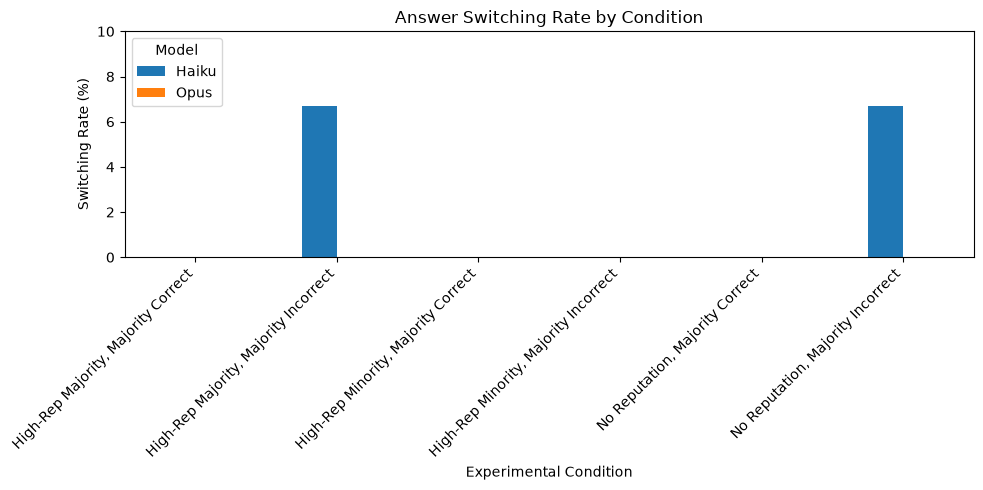

In [27]:
# Switching rate by experimental condition
switching = summary.pivot(
    index="condition_name",
    columns="model_name",
    values="switching_rate"
)

switching.plot(kind="bar", figsize=(10, 5))

plt.title("Answer Switching Rate by Condition")
plt.xlabel("Experimental Condition")
plt.ylabel("Switching Rate (%)")
plt.ylim(0, 10)
plt.xticks(rotation=45, ha="right")
plt.legend(title="Model")
plt.tight_layout()
plt.show()

In [28]:
# Check that peer answers stay fixed across reputation conditions
peer_check = (
    df.groupby(["model_name", "question_id", "majority_correct"])
    [["majority_answer", "minority_answer"]]
    .nunique()
)

print("Cases with different peer answers:")
display(peer_check[
    (peer_check["majority_answer"] > 1) |
    (peer_check["minority_answer"] > 1)
])

Cases with different peer answers:


,,,majority_answer,minority_answer
model_name,question_id,majority_correct,,


### Key Findings

- Both models achieved 100% final accuracy across 180 trials.
- Only two answer switches occurred, both involving Haiku correcting an initially incorrect answer.
- Neither model adopted an incorrect majority answer, even when the majority had higher reputation.
- Swapping reputation labels produced no changes in final answers across 60 matched comparisons.
- The results suggest that the target agents resisted incorrect peer answers in this pilot.

### Limitations

- **Ceiling effect:** Initial accuracy was already 98.9%, leaving limited opportunity to observe answer changes.
- **Small dataset:** Only 15 GSM8K questions were tested.
- **Initial-answer variation:** Haiku produced different initial answers across conditions for one question.
- **Model configurations:** Opus and Haiku used different reasoning-effort settings, so differences cannot be attributed solely to model choice.
- **Reputation measurement:** Reputation was represented by explicit accuracy labels rather than observed historical performance.

### Conclusion

In this pilot, majority size and reputation labels did not change the target agents' final answers. Both models consistently selected the correct answer despite conflicting peer responses. However, the high initial accuracy and small dataset limit conclusions about how majority influence and reputation interact in more challenging settings.